# Proyek Machine Learning: Prediksi Skor Produktivitas Mahasiswa

**Nama Mahasiswa:** Muhamad Hafizd Fahreza  
**Mata Kuliah:** Machine Learning  
**Dosen Pengampu:** Asep Erlan Maulana S.kom.,M.kom.  
**Dataset:** student_productivity_distraction_dataset_20000.csv  
**Jenis Pembelajaran:** Supervised Learning  
**Jenis Masalah:** Regresi  
**Target Prediksi:** productivity_score  

## Tujuan
Membangun dan membandingkan beberapa model regresi untuk memprediksi skor produktivitas mahasiswa berdasarkan kebiasaan belajar, penggunaan perangkat digital, durasi tidur, dan faktor distraksi digital lainnya.

> **Catatan:** Model dievaluasi menggunakan metrik standar regresi (MAE, RMSE, dan R²) sesuai alur praktikum lab.


## 1. Import library

Library yang digunakan untuk membaca dan mengolah data, membuat visualisasi, membangun model, serta mengevaluasi hasil prediksi.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Data collecting dan data loading

Letakkan file CSV di folder yang sama dengan notebook ini. Jika file berada di folder lain, ubah nilai `file_path` sesuai lokasi file.

In [2]:
file_path = "student_productivity_distraction_dataset_20000.csv"
df = pd.read_csv(file_path)

print("Dataset berhasil dibaca.")
print(f"Jumlah baris: {df.shape[0]}")
print(f"Jumlah kolom: {df.shape[1]}")
display(df.head())

Dataset berhasil dibaca.
Jumlah baris: 20000
Jumlah kolom: 18


,student_id,age,gender,study_hours_per_day,sleep_hours,phone_usage_hours,social_media_hours,youtube_hours,gaming_hours,breaks_per_day,coffee_intake_mg,exercise_minutes,assignments_completed,attendance_percentage,stress_level,focus_score,final_grade,productivity_score
0,1,23,Female,4.35,3.63,3.38,2.73,1.83,5.26,6,347,111,2,57.21,10,57,81.87,33.78
1,2,20,Male,6.14,6.58,5.48,1.51,3.13,1.73,13,403,28,10,91.27,10,49,60.90,48.99
2,3,29,Female,4.98,3.26,4.83,3.63,0.18,4.71,1,419,102,8,63.14,2,38,86.22,36.60
3,4,27,Female,3.19,4.58,10.06,3.95,5.75,2.52,9,178,28,18,40.51,6,50,71.77,19.87
4,5,24,Male,7.67,6.21,3.02,1.59,5.46,5.65,8,436,105,7,45.53,6,41,90.13,52.90


## 3. Pengenalan data

`shape` menunjukkan ukuran dataset, `info()` menunjukkan tipe data, dan `describe()` merangkum kolom numerik. Langkah ini membantu memahami isi dataset sebelum pemrosesan.

In [3]:
print("Ukuran dataset:", df.shape)
print("\nInformasi kolom:")
df.info()

print("\nRingkasan statistik kolom numerik:")
display(df.describe().T)

print("\nTipe data setiap kolom:")
display(df.dtypes.to_frame("tipe_data"))

Ukuran dataset: (20000, 18)

Informasi kolom:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             20000 non-null  int64  
 1   age                    20000 non-null  int64  
 2   gender                 20000 non-null  str    
 3   study_hours_per_day    20000 non-null  float64
 4   sleep_hours            20000 non-null  float64
 5   phone_usage_hours      20000 non-null  float64
 6   social_media_hours     20000 non-null  float64
 7   youtube_hours          20000 non-null  float64
 8   gaming_hours           20000 non-null  float64
 9   breaks_per_day         20000 non-null  int64  
 10  coffee_intake_mg       20000 non-null  int64  
 11  exercise_minutes       20000 non-null  int64  
 12  assignments_completed  20000 non-null  int64  
 13  attendance_percentage  20000 non-null  float64
 14  stress_level       

,count,mean,std,min,25%,50%,75%,max
student_id,20000.0,10000.500000,5773.647028,1.0,5000.7500,10000.500,15000.2500,20000.00
age,20000.0,23.007450,3.754890,17.0,20.0000,23.000,26.0000,29.00
study_hours_per_day,20000.0,5.254562,2.742876,0.5,2.9000,5.250,7.6400,10.00
sleep_hours,20000.0,6.517799,2.029784,3.0,4.7700,6.510,8.3100,10.00
phone_usage_hours,20000.0,6.250479,3.313082,0.5,3.3800,6.240,9.1025,12.00
social_media_hours,20000.0,4.003655,2.305154,0.0,2.0000,4.010,5.9700,8.00
youtube_hours,20000.0,2.990177,1.729815,0.0,1.4875,2.980,4.4800,6.00
gaming_hours,20000.0,2.988339,1.732803,0.0,1.4900,2.970,4.4900,6.00
breaks_per_day,20000.0,7.542400,4.016231,1.0,4.0000,8.000,11.0000,14.00
coffee_intake_mg,20000.0,249.654550,143.711231,0.0,125.0000,249.000,373.0000,499.00



Tipe data setiap kolom:


,tipe_data
student_id,int64
age,int64
gender,str
study_hours_per_day,float64
sleep_hours,float64
phone_usage_hours,float64
social_media_hours,float64
youtube_hours,float64
gaming_hours,float64
breaks_per_day,int64


## 4. Data cleaning

Pemeriksaan dilakukan pada nilai kosong, baris duplikat, dan nilai unik. Nilai kosong yang ditemukan pada fitur akan ditangani di dalam pipeline menggunakan imputasi. `student_id` hanya identitas, sehingga tidak digunakan sebagai fitur model.

In [4]:
print("Jumlah nilai kosong per kolom:")
display(df.isnull().sum().to_frame("nilai_kosong"))

print("Jumlah baris duplikat:", df.duplicated().sum())

# Menghapus baris duplikat jika ada.
df = df.drop_duplicates().copy()

print("Ukuran data setelah menghapus duplikat:", df.shape)

print("\nJumlah nilai unik pada kolom kategorikal:")
for col in df.select_dtypes(include="object").columns:
    print(f"{col}: {df[col].nunique()} nilai unik -> {df[col].unique()[:10]}")

Jumlah nilai kosong per kolom:


,nilai_kosong
student_id,0
age,0
gender,0
study_hours_per_day,0
sleep_hours,0
phone_usage_hours,0
social_media_hours,0
youtube_hours,0
gaming_hours,0
breaks_per_day,0


Jumlah baris duplikat: 0
Ukuran data setelah menghapus duplikat: (20000, 18)

Jumlah nilai unik pada kolom kategorikal:
gender: 3 nilai unik -> <StringArray>
['Female', 'Male', 'Other']
Length: 3, dtype: str


## 5. Data transformation dan pemeriksaan nilai

Periksa rentang nilai agar nilai yang tidak wajar dapat ditinjau. Jangan langsung menghapus nilai ekstrem tanpa memahami arti kolom dan sumber datanya.

In [5]:
numeric_cols = df.select_dtypes(include=np.number).columns
display(df[numeric_cols].agg(["min", "max", "mean", "median"]).T)

# Distribusi kolom kategorikal, misalnya gender.
for col in df.select_dtypes(include="object").columns:
    print(f"Distribusi {col}:")
    display(df[col].value_counts(dropna=False).to_frame("jumlah"))

,min,max,mean,median
student_id,1.0,20000.00,10000.500000,10000.500
age,17.0,29.00,23.007450,23.000
study_hours_per_day,0.5,10.00,5.254562,5.250
sleep_hours,3.0,10.00,6.517799,6.510
phone_usage_hours,0.5,12.00,6.250479,6.240
social_media_hours,0.0,8.00,4.003655,4.010
youtube_hours,0.0,6.00,2.990177,2.980
gaming_hours,0.0,6.00,2.988339,2.970
breaks_per_day,1.0,14.00,7.542400,8.000
coffee_intake_mg,0.0,499.00,249.654550,249.000


Distribusi gender:


,jumlah
gender,
Female,9640
Male,9582
Other,778


## 6. Exploratory Data Analysis (EDA)

Visualisasi membantu melihat distribusi target, sebaran beberapa fitur numerik, dan hubungan antarvariabel. Grafik korelasi hanya menunjukkan hubungan statistik, bukan sebab-akibat.

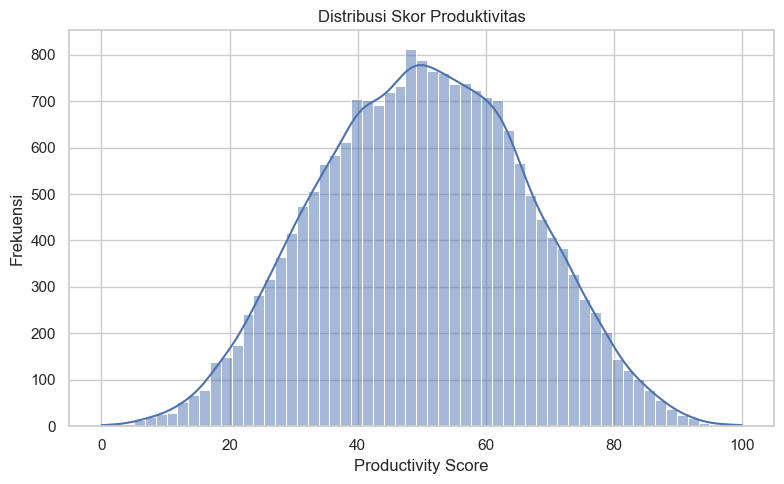

In [6]:
# Distribusi target produktivitas.
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="productivity_score", kde=True)
plt.title("Distribusi Skor Produktivitas")
plt.xlabel("Productivity Score")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

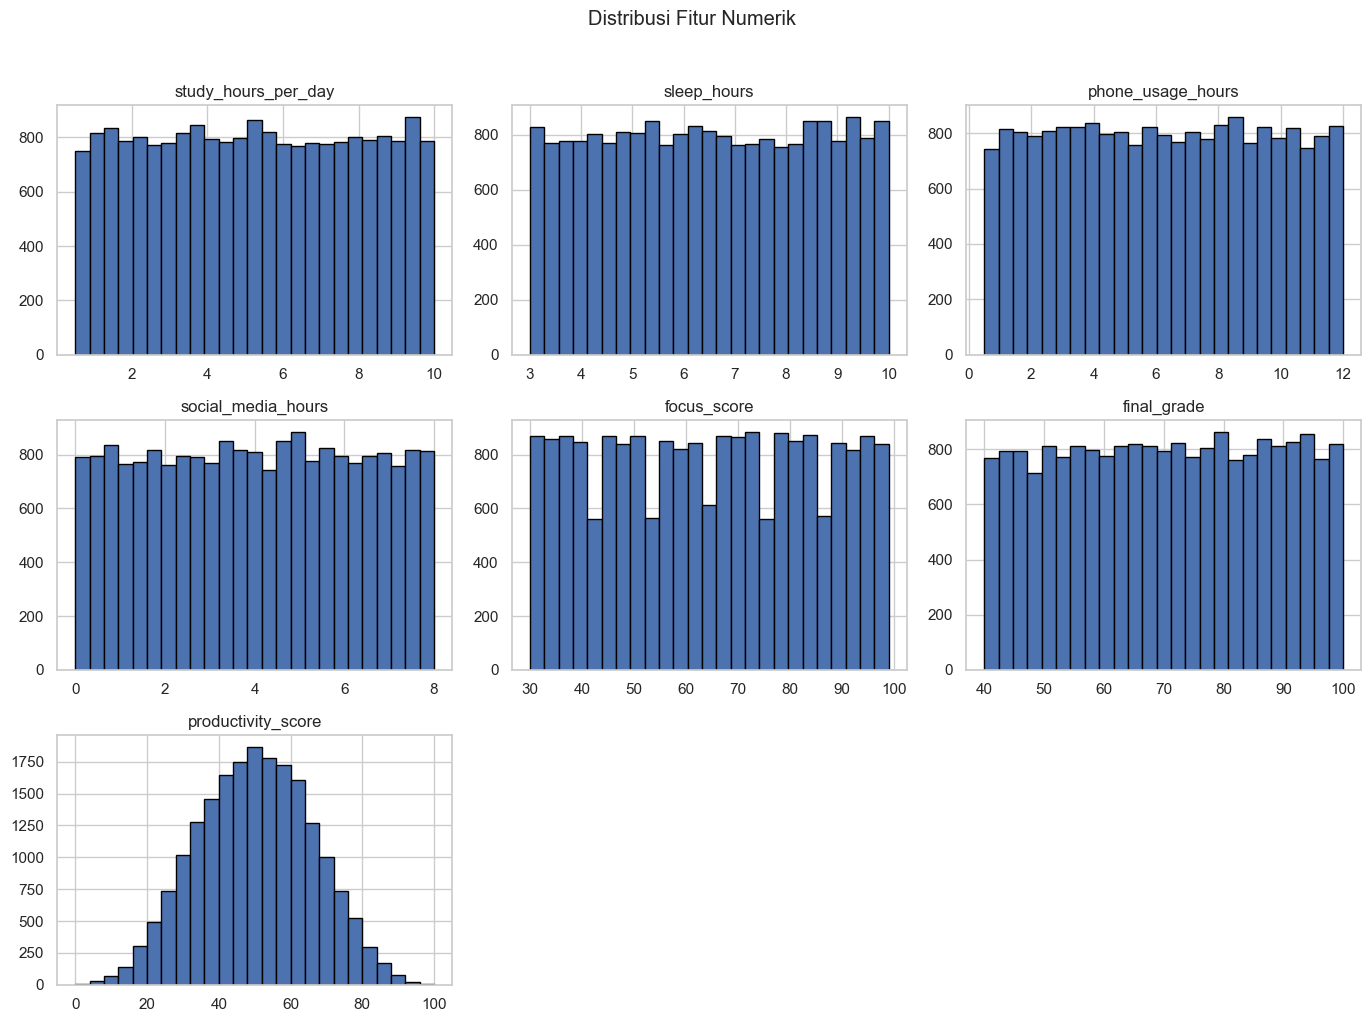

In [7]:
# Distribusi beberapa fitur numerik.
plot_cols = [
    "study_hours_per_day", "sleep_hours", "phone_usage_hours",
    "social_media_hours", "focus_score", "final_grade",
    "productivity_score"
]
df[plot_cols].hist(figsize=(14, 10), bins=25, edgecolor="black")
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.tight_layout()
plt.show()

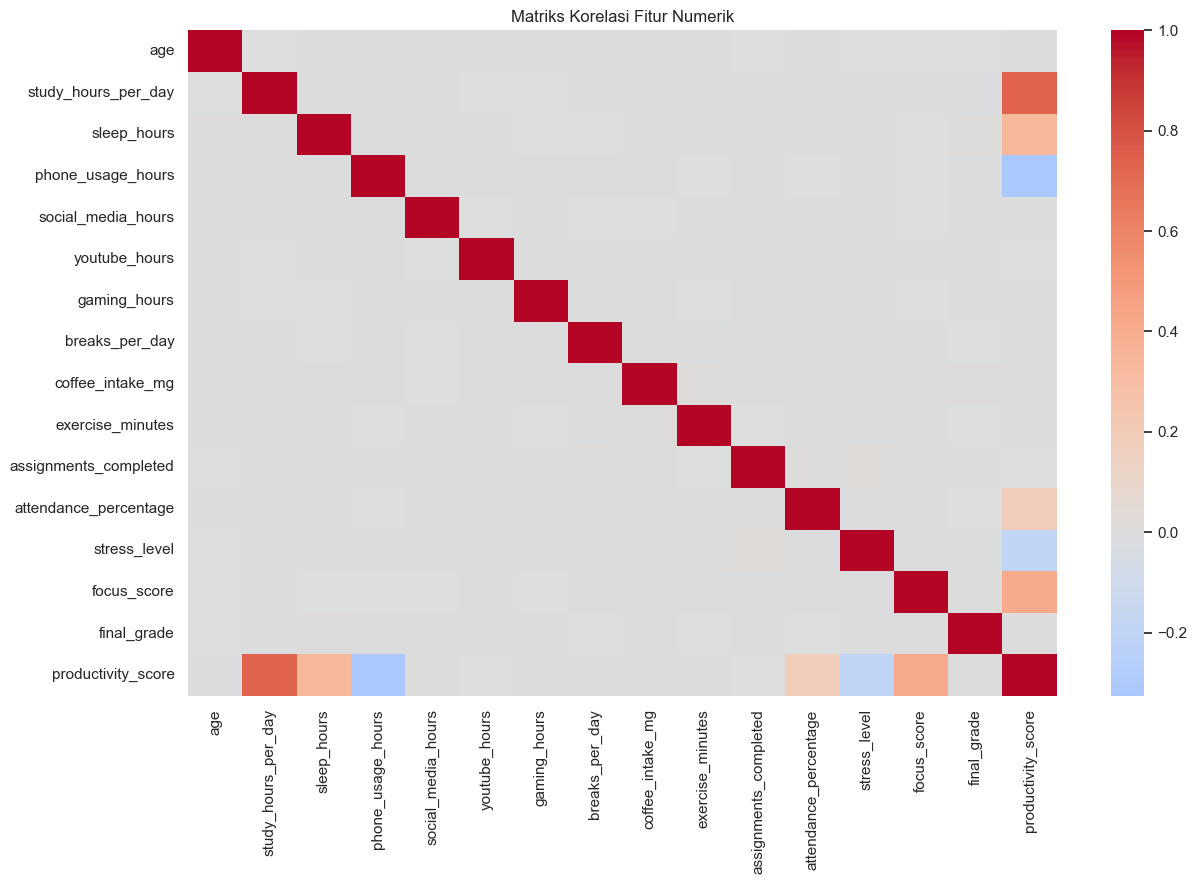

In [8]:
# Korelasi numerik sebagai eksplorasi awal.
plt.figure(figsize=(13, 9))
corr = df.select_dtypes(include=np.number).drop(columns=["student_id"], errors="ignore").corr()
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Matriks Korelasi Fitur Numerik")
plt.tight_layout()
plt.show()

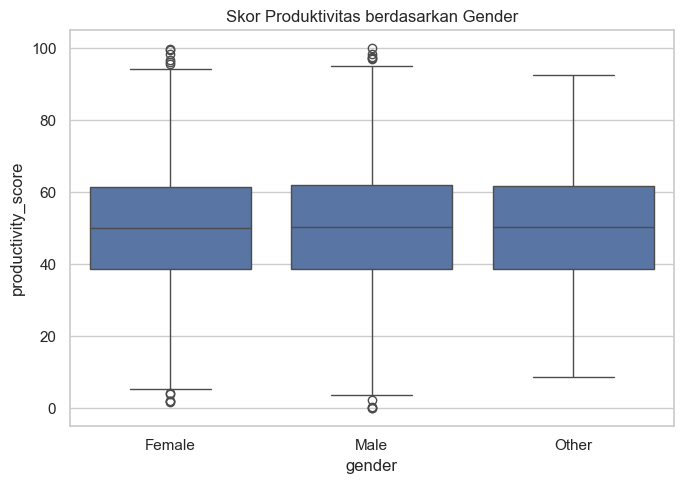

In [9]:
# Membandingkan skor produktivitas rata-rata berdasarkan gender jika kolom tersedia.
if "gender" in df.columns:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=df, x="gender", y="productivity_score")
    plt.title("Skor Produktivitas berdasarkan Gender")
    plt.tight_layout()
    plt.show()

## 7. Data processing: menentukan fitur dan target

Target yang diprediksi adalah `productivity_score`, yaitu nilai numerik sehingga masalah ini termasuk regresi. Kolom `student_id` dikeluarkan karena hanya merupakan identitas. Kolom target `productivity_score` juga tidak boleh dimasukkan ke fitur karena akan menyebabkan kebocoran target (*target leakage*).

Jika tujuan penelitian ingin memprediksi nilai akademik, target bisa diganti menjadi `final_grade`, tetapi fitur dan interpretasi hasil perlu disesuaikan.

In [10]:
target = "productivity_score"

# Pastikan kolom target tersedia.
if target not in df.columns:
    raise ValueError(f"Kolom target '{target}' tidak ditemukan di dataset.")

# Hapus baris yang targetnya kosong karena model perlu mengetahui nilai target saat training.
model_df = df.dropna(subset=[target]).copy()

# Pisahkan fitur (X) dan target (y), serta keluarkan kolom identitas.
drop_cols = [target, "student_id"]
X = model_df.drop(columns=drop_cols, errors="ignore")
y = model_df[target]

# Identifikasi kolom numerik dan kategorikal secara otomatis.
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Target:", target)
print("Jumlah fitur:", X.shape[1])
print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)
print("Jumlah sampel untuk modeling:", len(X))

Target: productivity_score
Jumlah fitur: 16
Fitur numerik: ['age', 'study_hours_per_day', 'sleep_hours', 'phone_usage_hours', 'social_media_hours', 'youtube_hours', 'gaming_hours', 'breaks_per_day', 'coffee_intake_mg', 'exercise_minutes', 'assignments_completed', 'attendance_percentage', 'stress_level', 'focus_score', 'final_grade']
Fitur kategorikal: ['gender']
Jumlah sampel untuk modeling: 20000


## 8. Data splitting

Data dibagi menjadi 80% data training dan 20% data testing. Data testing disimpan untuk mengevaluasi model pada data yang tidak digunakan saat pelatihan.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])

Jumlah data training: 16000
Jumlah data testing: 4000


## 9. Preprocessing dan pembangunan model

Preprocessing dibuat menggunakan `Pipeline` agar langkah imputasi, encoding, dan scaling dipelajari dari data training saja. Kolom kategorikal diubah dengan One-Hot Encoding. Scaling diterapkan pada fitur numerik untuk membantu Linear Regression, sedangkan model pohon juga dapat menggunakan pipeline yang sama.

In [12]:
# Pipeline fitur numerik: isi nilai kosong dengan median lalu standardisasi.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline fitur kategorikal: isi nilai kosong dengan modus lalu ubah menjadi kolom biner.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Gabungkan preprocessing untuk semua tipe fitur.
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Tiga model regresi untuk dibandingkan.
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=10),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        min_samples_leaf=2
    )
}

## 10. Training dan evaluasi model

Metrik yang digunakan:
- **MAE:** rata-rata selisih absolut prediksi dengan nilai aktual; makin kecil makin baik.
- **RMSE:** memberi penalti lebih besar pada kesalahan yang besar; makin kecil makin baik.
- **R²:** mengukur seberapa baik model menjelaskan variasi target; nilai mendekati 1 biasanya lebih baik. Nilainya bisa negatif jika model sangat buruk.

Tidak ada hasil yang dituliskan secara manual; tabel berikut dihitung dari dataset saat notebook dijalankan.

In [13]:
results = []
trained_models = {}

for name, estimator in models.items():
    # Setiap model memiliki preprocessing dan estimator dalam satu pipeline.
    model_pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator)
    ])

    # Latih model hanya menggunakan data training.
    model_pipeline.fit(X_train, y_train)

    # Prediksi pada data testing.
    predictions = model_pipeline.predict(X_test)

    # Hitung metrik evaluasi regresi.
    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })
    trained_models[name] = model_pipeline

results_df = pd.DataFrame(results).sort_values(by="RMSE", ascending=True)
display(results_df.round(4))

,Model,MAE,RMSE,R2
0,Linear Regression,0.0025,0.0029,1.0000
2,Random Forest Regressor,2.0005,2.5367,0.9750
1,Decision Tree Regressor,4.0246,5.0145,0.9024


## 11. Memilih dan melihat hasil model terbaik

Model dengan RMSE terkecil dipilih sebagai model terbaik pada pembagian data testing ini. Pemilihan ini tidak menjamin model akan selalu terbaik pada data lain.

In [14]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = best_model.predict(X_test)

print("Model terbaik berdasarkan RMSE:", best_model_name)

comparison = pd.DataFrame({
    "Nilai Aktual": y_test,
    "Hasil Prediksi": best_predictions,
    "Selisih Absolut": np.abs(y_test - best_predictions)
})
display(comparison.head(10).round(3))

Model terbaik berdasarkan RMSE: Linear Regression


,Nilai Aktual,Hasil Prediksi,Selisih Absolut
10650,49.95,49.948,0.002
2041,90.88,90.883,0.003
8668,60.03,60.028,0.002
1114,50.36,50.355,0.005
13902,35.69,35.694,0.004
11963,57.93,57.926,0.004
11072,41.27,41.274,0.004
3002,27.34,27.344,0.004
19771,37.50,37.502,0.002
8115,44.97,44.967,0.003


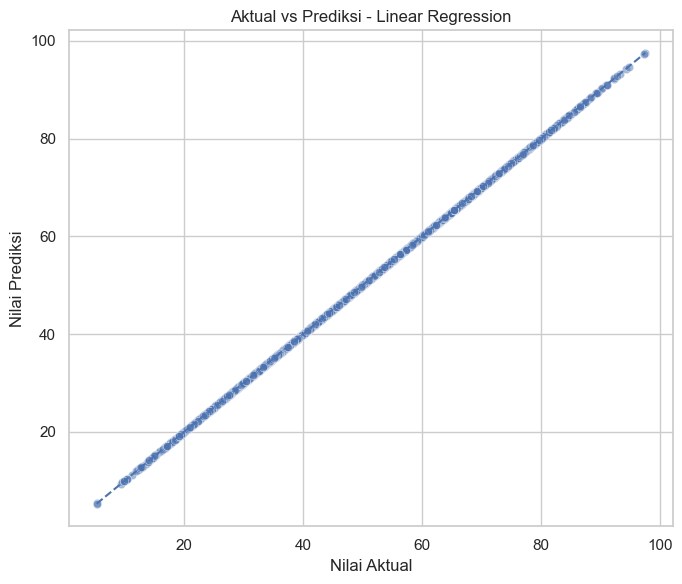

In [15]:
# Visualisasi nilai aktual dibandingkan hasil prediksi.
plt.figure(figsize=(7, 6))
sns.scatterplot(x=y_test, y=best_predictions, alpha=0.5)
min_val = min(y_test.min(), best_predictions.min())
max_val = max(y_test.max(), best_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.xlabel("Nilai Aktual")
plt.ylabel("Nilai Prediksi")
plt.title(f"Aktual vs Prediksi - {best_model_name}")
plt.tight_layout()
plt.show()

## 12. Kesimpulan otomatis awal

Kesimpulan berikut mengambil nama model dan nilai metrik dari hasil eksekusi. Lengkapi kesimpulan dengan mengaitkan hasil tersebut pada konteks dataset dan batasan penelitian.

In [16]:
best_row = results_df.iloc[0]

print(f"Model dengan RMSE terendah pada data testing adalah {best_row['Model']}.")
print(f"MAE  : {best_row['MAE']:.4f}")
print(f"RMSE : {best_row['RMSE']:.4f}")
print(f"R2   : {best_row['R2']:.4f}")

print("\nPanduan interpretasi:")
print("- MAE dan RMSE berada dalam satuan skor productivity_score.")
print("- R2 menunjukkan proporsi variasi target yang dijelaskan model secara relatif.")
print("- Hasil ini berlaku pada pembagian data dan konfigurasi model yang digunakan.")
print("- Hindari menyimpulkan sebab-akibat hanya dari korelasi atau hasil prediksi.")

Model dengan RMSE terendah pada data testing adalah Linear Regression.
MAE  : 0.0025
RMSE : 0.0029
R2   : 1.0000

Panduan interpretasi:
- MAE dan RMSE berada dalam satuan skor productivity_score.
- R2 menunjukkan proporsi variasi target yang dijelaskan model secara relatif.
- Hasil ini berlaku pada pembagian data dan konfigurasi model yang digunakan.
- Hindari menyimpulkan sebab-akibat hanya dari korelasi atau hasil prediksi.


## 13. Catatan untuk laporan dan GitHub

Tuliskan sumber dataset yang sebenarnya pada laporan. Sertakan tujuan, deskripsi kolom, hasil data cleaning, grafik EDA, pembagian data, algoritma, tabel evaluasi, serta kesimpulan. Sebelum mengunggah, pastikan lisensi dataset mengizinkan pembagian ulang dan jangan mengunggah informasi pribadi yang sensitif.

### Cara menjalankan
1. Simpan notebook ini dan file CSV dalam folder yang sama.
2. Buka notebook menggunakan Jupyter Notebook.
3. Jalankan sel dari atas ke bawah (`Kernel` → `Restart & Run All` atau `Run All Cells`).
4. Jika library belum tersedia, jalankan perintah berikut pada terminal environment Jupyter: `pip install pandas numpy matplotlib seaborn scikit-learn`.